# Predicting steel fatigue strength from composition and processing: random forest vs neural network

**Data.** `data.csv` holds 437 samples with 25 input features (chemical composition, heat-treatment / processing parameters, inclusion measures) and the target *fatigue strength at 10^7 cycles* (MPa). It matches the public NIMS steel fatigue dataset (Agrawal et al., 2014, *Integrating Materials and Manufacturing Innovation* 3:8). It mixes several carbon, low-alloy and carburizing steels, so it is **not** a single-grade dataset. Upload `data.csv` to `/content/` before running.

**Reproducibility.** All random seeds are fixed in the third cell. Run the notebook top to bottom (Runtime > Run all).

**Evaluation.** Models are scored on a random 80/20 hold-out and the random forest is also cross-validated with shuffled and with contiguous folds. All numbers quoted elsewhere come from the *Final results* section.

## Importing libraries

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.ensemble import RandomForestRegressor

plt.style.use('ggplot')
fontdict = {
    'family': 'sans-serif',
    'color':  'black',
    'weight': 'normal',
    'size': 14,
}

### Fixed random seeds

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow together
try:
    tf.config.experimental.enable_op_determinism()   # deterministic TensorFlow ops (can be slightly slower)
except Exception as e:
    print('op determinism not enabled:', e)

## Loading data

In [3]:
df_1 = pd.read_csv('/content/data.csv')

In [4]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 437 entries, 0 to 436
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Sl. No.   437 non-null    int64  
 1   NT        437 non-null    int64  
 2   THT       437 non-null    int64  
 3   THt       437 non-null    int64  
 4   THQCr     437 non-null    int64  
 5   CT        437 non-null    int64  
 6   Ct        437 non-null    float64
 7   DT        437 non-null    float64
 8   Dt        437 non-null    float64
 9   QmT       437 non-null    int64  
 10  TT        437 non-null    int64  
 11  Tt        437 non-null    int64  
 12  TCr       437 non-null    float64
 13  C         437 non-null    float64
 14  Si        437 non-null    float64
 15  Mn        437 non-null    float64
 16  P         437 non-null    float64
 17  S         437 non-null    float64
 18  Ni        437 non-null    float64
 19  Cr        437 non-null    float64
 20  Cu        437 non-null    float6

In [5]:
df_1.shape

(437, 27)

In [6]:
df_1.isnull().sum()

,0
Sl. No.,0
NT,0
THT,0
THt,0
THQCr,0
CT,0
Ct,0
DT,0
Dt,0
QmT,0


In [7]:
df_1.columns

Index(['Sl. No.', 'NT', 'THT', 'THt', 'THQCr', 'CT', 'Ct', 'DT', 'Dt', 'QmT',
       'TT', 'Tt', 'TCr', 'C', 'Si', 'Mn', 'P', 'S', 'Ni', 'Cr', 'Cu', 'Mo',
       'RedRatio', 'dA', 'dB', 'dC', 'Fatigue'],
      dtype='object')

In [8]:
df_3=df_1.copy()
df_3.columns=['Sl. No.','Normalizing Temp','Through Hardening Temp','Through Hardening Time','Cooling Rate for Through Hardening','Carburization Temp',
             'Carburization Time','Diffusion Temp','Diffusion time','Quenching Media Temp','Tempering Temp','Tempering Time','Cooling Rate for Tempering',
             'C', 'Si', 'Mn', 'P', 'S', 'Ni', 'Cr', 'Cu', 'Mo','Reduction Ratio',
              'Area Proportion of Inclusions Deformed by Plastic Work','Area Proportion of Inclusions Occurring in Discontinuous Array',
              'Area Proportion of Isolated Inclusions','Fatigue Strength (10^7 Cycles)']

## EDA

In [9]:
df_3.iloc[:,1:].describe().T

,count,mean,std,min,25%,50%,75%,max
Normalizing Temp,437.0,872.299771,26.212073,825.000,865.000,870.000,870.000,930.000
Through Hardening Temp,437.0,737.643021,280.036541,30.000,845.000,845.000,855.000,865.000
Through Hardening Time,437.0,25.949657,10.263824,0.000,30.000,30.000,30.000,30.000
Cooling Rate for Through Hardening,437.0,10.654462,7.841437,0.000,8.000,8.000,8.000,24.000
Carburization Temp,437.0,128.855835,281.743539,30.000,30.000,30.000,30.000,930.000
Carburization Time,437.0,40.502059,126.924697,0.000,0.000,0.000,0.000,540.000
Diffusion Temp,437.0,123.699844,267.128933,30.000,30.000,30.000,30.000,903.333
Diffusion time,437.0,4.843936,15.700076,0.000,0.000,0.000,0.000,70.200
Quenching Media Temp,437.0,35.491991,19.419277,30.000,30.000,30.000,30.000,140.000
Tempering Temp,437.0,536.842105,164.101963,30.000,550.000,600.000,650.000,680.000


### Histogram of columns

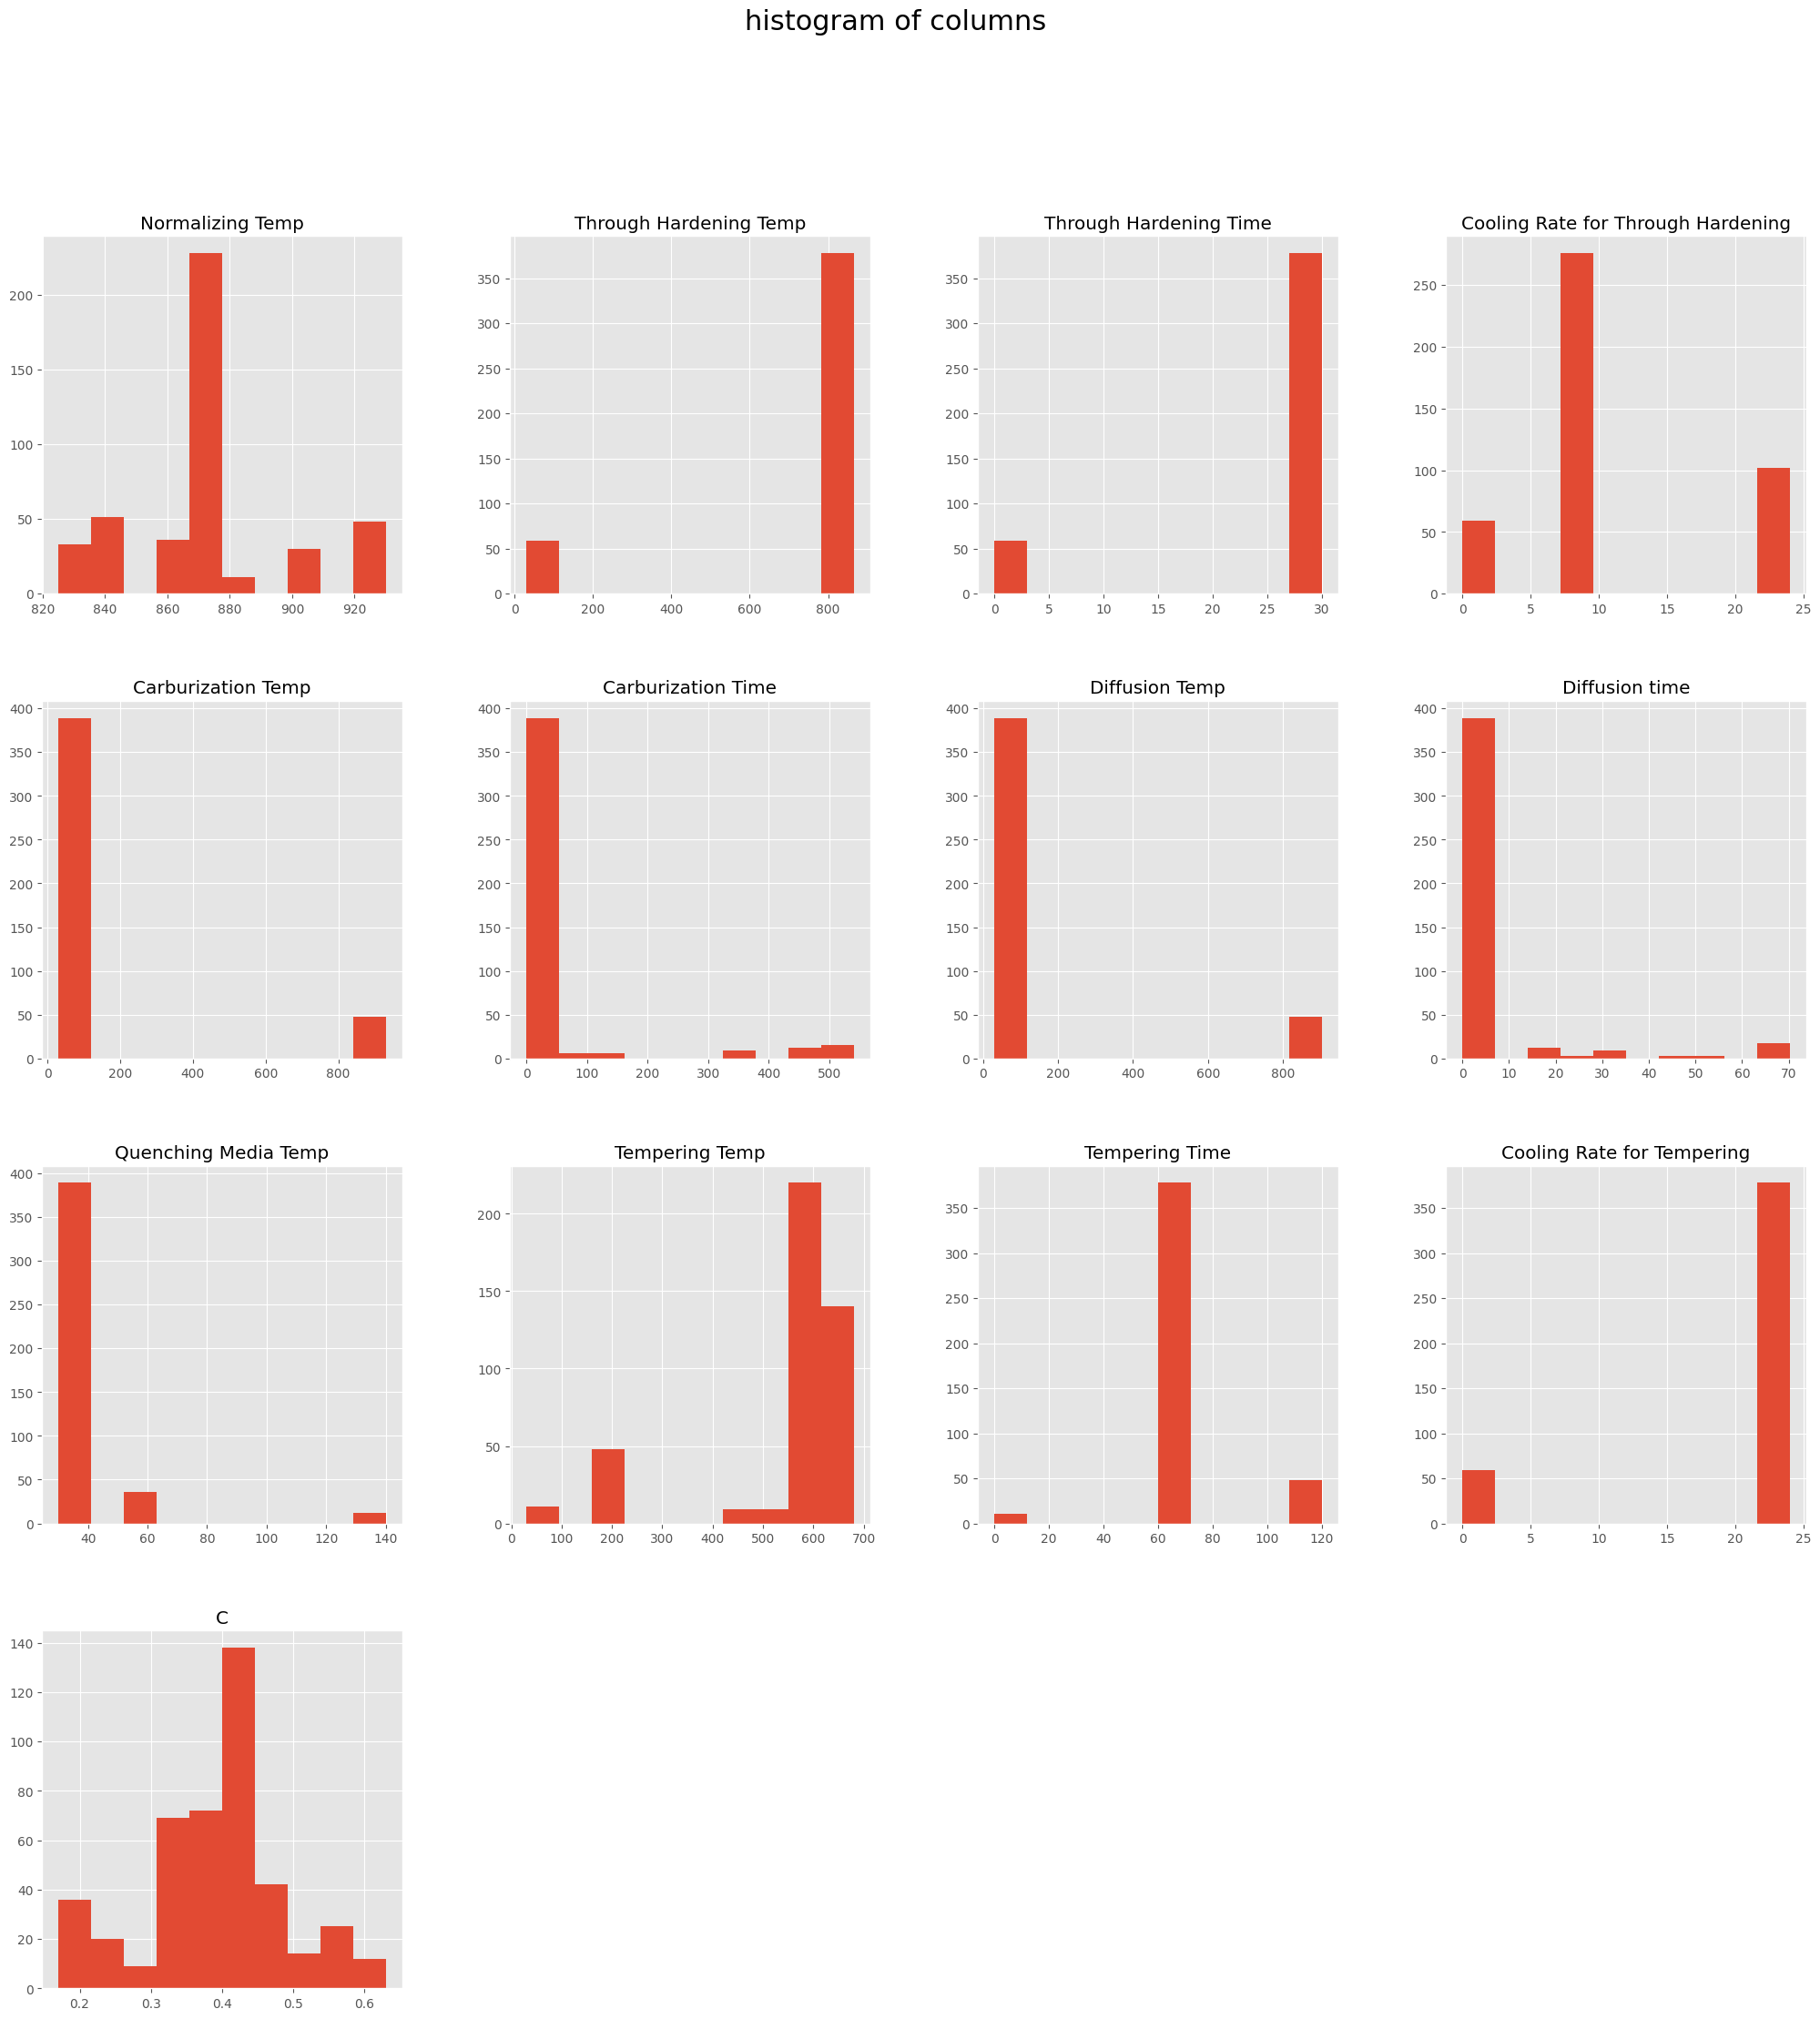

In [10]:
df_3.iloc[:,1:14].hist(figsize=(25,25))
plt.suptitle('histogram of columns',fontsize=22)
plt.show()

###  Correlation between different features and Fatigue Strength
#### green columns indicate positive correlation (direct proportionality)
#### red columns indicate negative correlation (inverse proportionality)

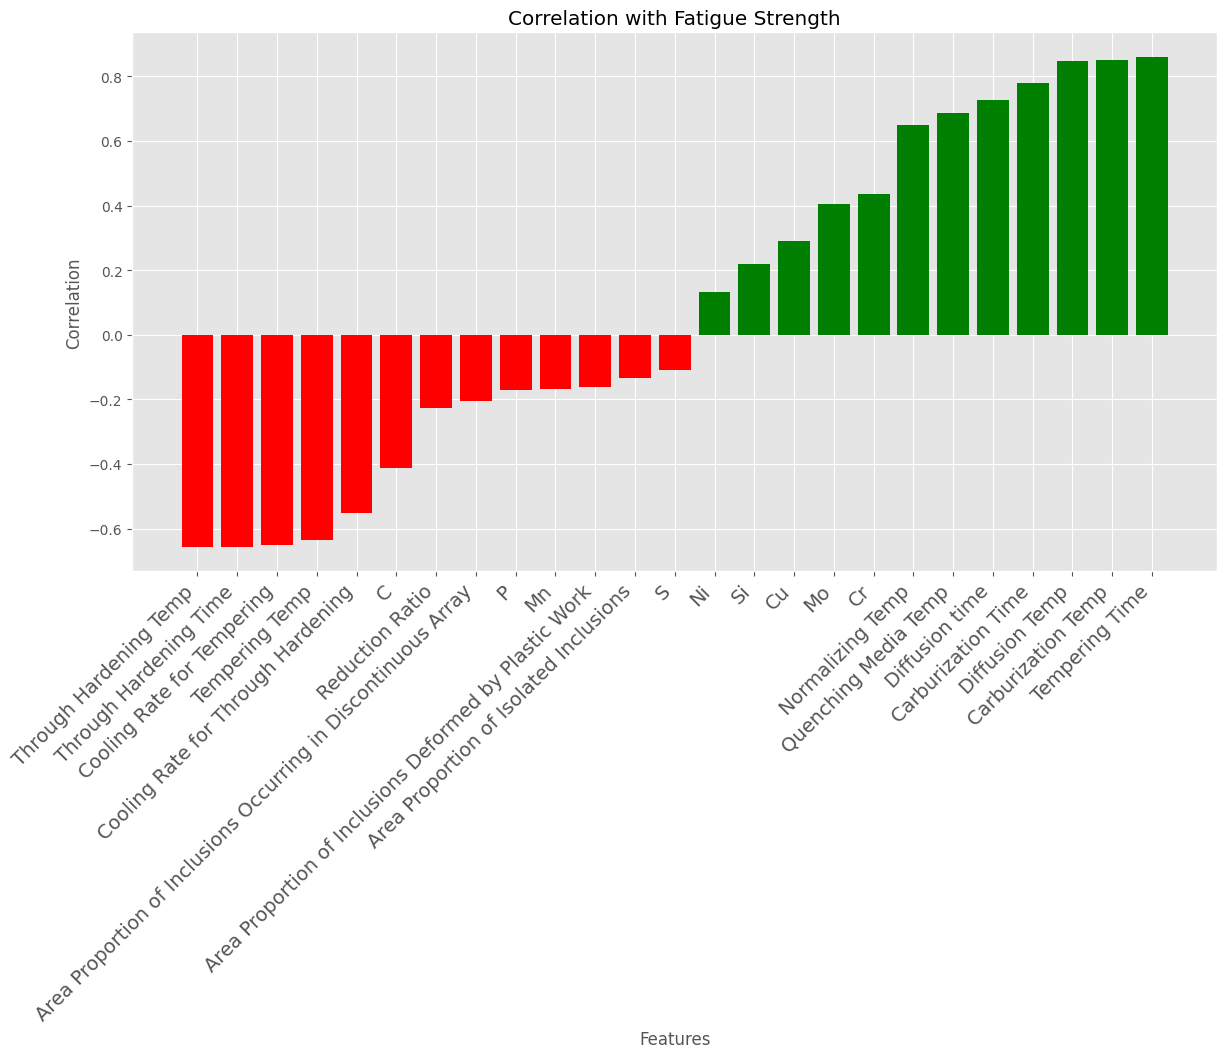

In [11]:
correlation = df_3.drop(columns=['Sl. No.','Fatigue Strength (10^7 Cycles)']).corrwith(df_3['Fatigue Strength (10^7 Cycles)'])
correlation.sort_values(inplace=True)
plt.figure(figsize=(14,7))
plt.bar(correlation.index, correlation, color=['green' if val >= 0 else 'red' for val in correlation])
plt.xlabel('Features')
plt.ylabel('Correlation')
plt.title('Correlation with Fatigue Strength')

plt.xticks(rotation=45, ha='right',fontsize=14)
plt.show()

### Data of top 10 fatigue strength samples

In [12]:
df_3.sort_values('Fatigue Strength (10^7 Cycles)',ascending=False).head(10).iloc[:,:14]

,Sl. No.,Normalizing Temp,Through Hardening Temp,Through Hardening Time,Cooling Rate for Through Hardening,Carburization Temp,Carburization Time,Diffusion Temp,Diffusion time,Quenching Media Temp,Tempering Temp,Tempering Time,Cooling Rate for Tempering,C
396,397,930,30,0,0,930,540.0,850.000,15.0,140,160,120,0.5,0.23
428,429,930,30,0,0,930,340.2,895.812,70.2,60,160,120,0.5,0.21
390,391,930,30,0,0,930,139.8,850.000,15.0,60,160,120,0.5,0.23
393,394,930,30,0,0,930,469.8,850.000,15.0,60,160,120,0.5,0.23
423,424,930,30,0,0,930,499.8,895.812,70.2,60,200,120,0.5,0.23
399,400,930,30,0,0,930,469.8,850.000,15.0,60,200,120,0.5,0.23
434,435,930,30,0,0,930,340.2,895.812,70.2,60,200,120,0.5,0.21
406,407,930,30,0,0,930,450.0,895.517,34.8,60,160,120,0.5,0.18
414,415,930,30,0,0,930,100.2,895.517,34.8,60,160,120,0.5,0.23
394,395,930,30,0,0,930,469.8,850.000,15.0,60,160,120,0.5,0.17


In [13]:
df_3.sort_values('Fatigue Strength (10^7 Cycles)',ascending=False).head(10).iloc[:,14:]

,Si,Mn,P,S,Ni,Cr,Cu,Mo,Reduction Ratio,Area Proportion of Inclusions Deformed by Plastic Work,Area Proportion of Inclusions Occurring in Discontinuous Array,Area Proportion of Isolated Inclusions,Fatigue Strength (10^7 Cycles)
396,0.35,0.51,0.008,0.012,1.69,0.55,0.11,0.18,860,0.070,0.01,0.000,1190
428,0.31,0.81,0.012,0.019,0.06,1.17,0.07,0.17,690,0.080,0.00,0.000,1144
390,0.35,0.51,0.008,0.012,1.69,0.55,0.11,0.18,860,0.070,0.01,0.000,1139
393,0.35,0.51,0.008,0.012,1.69,0.55,0.11,0.18,860,0.070,0.01,0.000,1124
423,0.20,0.80,0.013,0.018,0.04,1.14,0.07,0.02,690,0.070,0.00,0.010,1120
399,0.35,0.51,0.008,0.012,1.69,0.55,0.11,0.18,860,0.070,0.01,0.000,1110
434,0.31,0.81,0.012,0.019,0.06,1.17,0.07,0.17,690,0.080,0.00,0.000,1104
406,0.26,0.76,0.009,0.014,0.56,0.62,0.12,0.17,690,0.060,0.00,0.000,1089
414,0.20,0.80,0.013,0.018,0.04,1.14,0.07,0.02,690,0.070,0.00,0.010,1086
394,0.28,0.55,0.002,0.016,1.64,0.45,0.05,0.16,440,0.017,0.00,0.008,1082


## Creating Regression Model

### Splitting data into train and test

In [14]:
x=df_3.drop(columns=['Sl. No.','Fatigue Strength (10^7 Cycles)'])
y=df_3['Fatigue Strength (10^7 Cycles)']

In [15]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=SEED)

### Creating a Random forest regression model

In [16]:
forest_reg=RandomForestRegressor(n_estimators=100, max_depth=100, random_state=SEED)
forest_reg.fit(x_train,y_train)

RandomForestRegressor(max_depth=100, random_state=42)

In [17]:
y_pred_1=forest_reg.predict(x_test)
rmse_forest=np.sqrt(mean_squared_error(y_test,y_pred_1))
r2_forest=r2_score(y_test,y_pred_1)

print('Random forest, random 80/20 hold-out:')
print('  R squared:', round(r2_forest,4), '| RMSE (MPa):', round(rmse_forest,2))

Random forest, random 80/20 hold-out:
  R squared: 0.9846 | RMSE (MPa): 25.2


### Features that affect fatigue strength most  

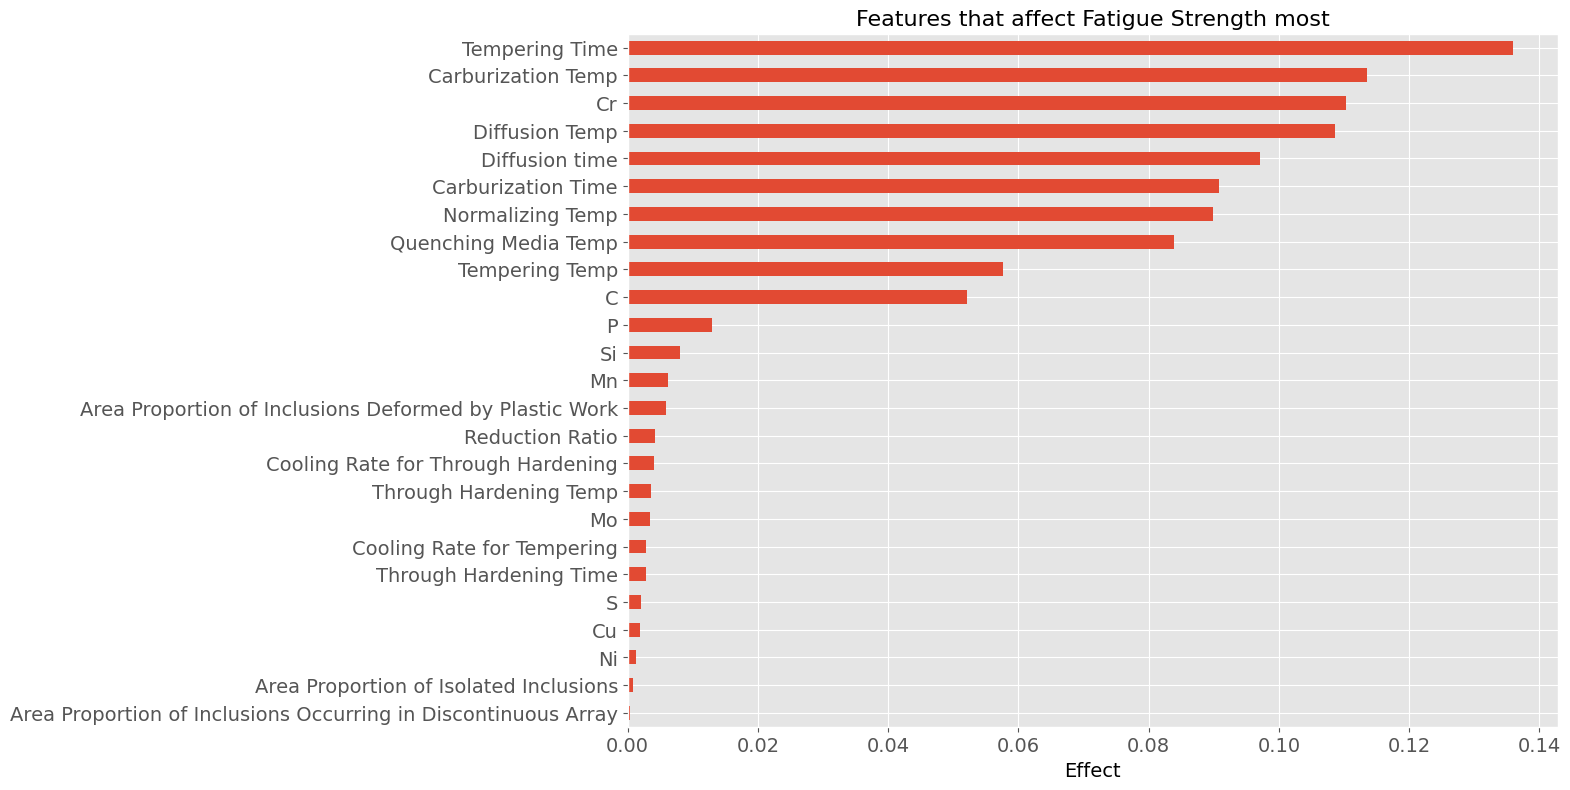

Tempering Time        0.136
Carburization Temp    0.113
Cr                    0.110
Diffusion Temp        0.109
Diffusion time        0.097


In [18]:
labels=x_train.columns
importanes=forest_reg.feature_importances_
importance_dict=dict(zip(labels,importanes))
importance_series=pd.Series(importance_dict)
importance_series=importance_series.sort_values(ascending=True)
plt.figure(figsize=(12,9))
importance_series.plot(kind='barh')
plt.title('Features that affect Fatigue Strength most',fontsize=16)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Effect',fontdict=fontdict)
plt.show()
print(importance_series.sort_values(ascending=False).head(5).round(3).to_string())

## Creating an artificial neural network for regression

In [19]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaler_1 = MinMaxScaler()

X_train_scaled = scaler.fit_transform(x_train.values)
X_test_scaled = scaler.transform(x_test.values)
y_train_scaled=scaler_1.fit_transform(y_train.values.reshape(-1,1))
y_test_scaled=scaler_1.transform(y_test.values.reshape(-1,1))

In [20]:
model = Sequential([
    Input(shape=(x_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1)  # Output layer with 1 neuron for regression
])
early_stopping=EarlyStopping(restore_best_weights=True,monitor='val_mse',mode='min',patience=40,verbose=1)
model.compile(optimizer='adam', loss='mean_squared_error',metrics=['mse'])
history = model.fit(X_train_scaled, y_train_scaled, epochs=200, batch_size=32, validation_split=0.2,callbacks=[early_stopping])

Epoch 1/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.1181 - mse: 0.1181 - val_loss: 0.0328 - val_mse: 0.0328
Epoch 2/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0360 - mse: 0.0360 - val_loss: 0.0164 - val_mse: 0.0164
Epoch 3/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0245 - mse: 0.0245 - val_loss: 0.0111 - val_mse: 0.0111
Epoch 4/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0148 - mse: 0.0148 - val_loss: 0.0042 - val_mse: 0.0042
Epoch 5/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0100 - mse: 0.0100 - val_loss: 0.0039 - val_mse: 0.0039
Epoch 6/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0076 - mse: 0.0076 - val_loss: 0.0051 - val_mse: 0.0051
Epoch 7/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0066 - mse: 0.0066 - val_loss: 0.0047 - val_mse: 0.0047
Epoch 8/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0055 - mse: 0.0055 - val_loss: 0.0040 - val_mse: 0.0040
Epoch 9/200
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0048 - mse: 

In [21]:
def plot_loss_and_mse_curves(history):
    """
    Plots the loss and MSE curves from a model's training history.

    Parameters:
    - history: The history object returned by the fit method of a Keras model.
               It should contain the keys 'loss', 'val_loss', 'mse', and 'val_mse'.
    """
    # Get the values from the history
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    mse = history.history.get('mse')
    val_mse = history.history.get('val_mse')

    epochs = range(1, len(loss) + 1)

    # Plot the loss values
    plt.figure(figsize=(12, 6))

#     plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, 'b', label='Training Loss')
    plt.plot(epochs, val_loss, 'r', label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot the MSE values if they exist
#     if mse and val_mse:
#         plt.subplot(1, 2, 2)
#         plt.plot(epochs, mse, 'b', label='Training MSE')
#         plt.plot(epochs, val_mse, 'r', label='Validation MSE')
#         plt.title('Training and Validation MSE')
#         plt.xlabel('Epochs')
#         plt.ylabel('Mean Squared Error')
#         plt.legend()

#     plt.tight_layout()
#     plt.show()

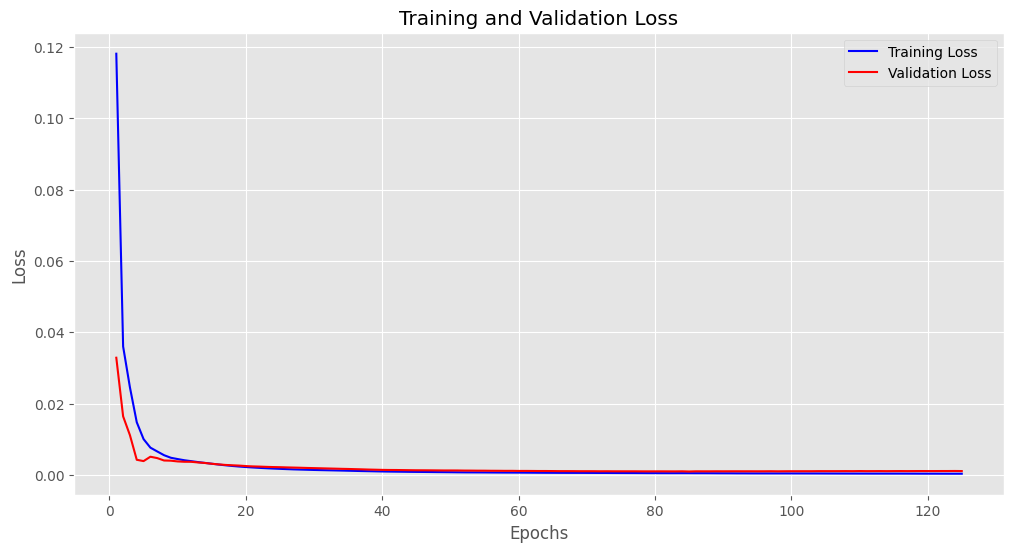

In [22]:
plot_loss_and_mse_curves(history)

In [23]:
y_pred_2=model.predict(X_test_scaled, verbose=0)
y_true_real=scaler_1.inverse_transform(y_test_scaled)
y_pred_real=scaler_1.inverse_transform(y_pred_2)
r2_ann=r2_score(y_true_real,y_pred_real)
rmse_ann=np.sqrt(mean_squared_error(y_true_real,y_pred_real))

print('Artificial neural network, random 80/20 hold-out:')
print('  R squared:', round(r2_ann,4), '| RMSE (MPa):', round(rmse_ann,2))

Artificial neural network, random 80/20 hold-out:
  R squared: 0.9763 | RMSE (MPa): 31.3


## Final results: hold-out vs cross-validation

The same random forest is evaluated four ways: a random 80/20 hold-out, 5-fold CV with shuffled folds, and 5-fold CV with contiguous (unshuffled) folds, which is what `cross_val_score(..., cv=5)` does for a regressor. The cell after this one checks how the file is ordered.

In [24]:
def rmse(a, b):
    return float(np.sqrt(mean_squared_error(a, b)))

# --- random 80/20 hold-out (same split for both models) ---
pred_rf  = forest_reg.predict(x_test)
pred_ann = scaler_1.inverse_transform(model.predict(X_test_scaled, verbose=0)).ravel()

rows = [
    ('Random forest',  'random 80/20 hold-out', r2_score(y_test, pred_rf),  rmse(y_test, pred_rf)),
    ('Neural network', 'random 80/20 hold-out', r2_score(y_test, pred_ann), rmse(y_test, pred_ann)),
]

# --- 5-fold cross-validation of the random forest, two ways ---
cv_shuffled   = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_contiguous = KFold(n_splits=5, shuffle=False)

for name, cv in [('5-fold CV, shuffled folds', cv_shuffled), ('5-fold CV, contiguous folds', cv_contiguous)]:
    r2_cv   = cross_val_score(forest_reg, x, y, cv=cv, scoring='r2').mean()
    rmse_cv = -cross_val_score(forest_reg, x, y, cv=cv, scoring='neg_root_mean_squared_error').mean()
    rows.append(('Random forest', name, r2_cv, rmse_cv))

summary = pd.DataFrame(rows, columns=['model', 'evaluation', 'R2', 'RMSE (MPa)']).round(3)
print(summary.to_string(index=False))

fold_rmse = -cross_val_score(forest_reg, x, y, cv=cv_contiguous, scoring='neg_root_mean_squared_error')
print('\nRMSE of each contiguous fold (MPa):', np.round(fold_rmse, 1))
print('Target standard deviation (MPa):', round(float(y.std()), 1), '(a model that always predicts the mean scores about this RMSE)')

         model                  evaluation     R2  RMSE (MPa)
 Random forest       random 80/20 hold-out  0.985      25.196
Neural network       random 80/20 hold-out  0.976      31.305
 Random forest   5-fold CV, shuffled folds  0.977      27.295
 Random forest 5-fold CV, contiguous folds -1.586     135.979

RMSE of each contiguous fold (MPa): [231.1  29.6  46.1  21.1 352. ]
Target standard deviation (MPa): 186.6 (a model that always predicts the mean scores about this RMSE)


In [25]:
# How is the file ordered? (explains the gap between shuffled and contiguous folds)
carb = (df_3['Carburization Time'] > 0).values            # carburized steels
pos  = np.flatnonzero(carb)
print('Carburized rows:', int(carb.sum()), 'of', len(df_3), f'({carb.mean():.0%})')
print('Row positions of carburized rows: first', int(pos[0]), '| last', int(pos[-1]), '| one contiguous block:', bool(np.all(np.diff(pos) == 1)))
print('Mean fatigue strength (MPa): carburized =', round(float(y.values[carb].mean()), 1), '| not carburized =', round(float(y.values[~carb].mean()), 1))

fold_of_row = np.zeros(len(df_3), dtype=int)
for k, (_, test_idx) in enumerate(cv_contiguous.split(x)):
    fold_of_row[test_idx] = k
print('Carburized rows in each contiguous fold:', np.bincount(fold_of_row[carb], minlength=5))

Carburized rows: 48 of 437 (11%)
Row positions of carburized rows: first 389 | last 436 | one contiguous block: True
Mean fatigue strength (MPa): carburized = 1004.1 | not carburized = 497.2
Carburized rows in each contiguous fold: [ 0  0  0  0 48]


### Seed sensitivity

Single-run numbers move with the random seed, especially for the neural network. This cell repeats the hold-out evaluation with five seeds (same data split) and reports mean and standard deviation. It takes a few minutes.

In [26]:
def train_ann(seed):
    tf.keras.utils.set_random_seed(seed)
    m = Sequential([Input(shape=(x_train.shape[1],)),
                    Dense(64, activation='relu'), Dense(32, activation='relu'),
                    Dense(16, activation='relu'), Dense(8, activation='relu'), Dense(1)])
    m.compile(optimizer='adam', loss='mean_squared_error', metrics=['mse'])
    es = EarlyStopping(restore_best_weights=True, monitor='val_mse', mode='min', patience=40, verbose=0)
    m.fit(X_train_scaled, y_train_scaled, epochs=200, batch_size=32, validation_split=0.2, callbacks=[es], verbose=0)
    p = scaler_1.inverse_transform(m.predict(X_test_scaled, verbose=0)).ravel()
    return r2_score(y_test, p), rmse(y_test, p)

seed_rows = []
for s in range(5):
    rf = RandomForestRegressor(n_estimators=100, max_depth=100, random_state=s).fit(x_train, y_train)
    p_rf = rf.predict(x_test)
    r2_a, rmse_a = train_ann(s)
    seed_rows.append((s, r2_score(y_test, p_rf), rmse(y_test, p_rf), r2_a, rmse_a))

seed_df = pd.DataFrame(seed_rows, columns=['seed', 'RF R2', 'RF RMSE', 'ANN R2', 'ANN RMSE']).set_index('seed')
print(seed_df.round(3).to_string())
print('\nmean and standard deviation over 5 seeds:')
print(pd.DataFrame({'mean': seed_df.mean(), 'sd': seed_df.std()}).round(3).to_string())

      RF R2  RF RMSE  ANN R2  ANN RMSE
seed                                  
0     0.985   24.931   0.978    30.173
1     0.985   24.640   0.985    24.864
2     0.985   24.815   0.975    32.308
3     0.985   24.540   0.977    30.734
4     0.986   24.384   0.977    30.895

mean and standard deviation over 5 seeds:
            mean     sd
RF R2      0.985  0.000
RF RMSE   24.662  0.217
ANN R2     0.978  0.004
ANN RMSE  29.795  2.866


## Summary and limitations

- **Data.** 437 samples and 25 input features from several steel families (carbon, low-alloy, carburizing). The target is fatigue strength at 10^7 cycles (MPa). This is not a single-grade dataset.
- **Random-split performance is strong.** On a random 80/20 hold-out both models fit well (tables above); in these runs the random forest scores slightly better than the neural network on both R2 and RMSE.
- **It is also optimistic.** The file is not randomly ordered (see the ordering check). Shuffled 5-fold CV agrees with the hold-out, but contiguous folds, which remove whole blocks of rows, give an RMSE several times larger. Random-split scores therefore overstate how well the models would predict samples unlike those seen in training.
- **Feature importances.** The largest random-forest importances are led by carburizing and diffusion process parameters, which sit at baseline values for non-carburized steels. They partly act as sample-group identifiers, so they should not be read as causal effects.
- **Seeds.** Single-run numbers shift with the seed (see the seed-sensitivity table); quote the seeded results above or the five-seed mean and standard deviation.
- **Next steps.** Validation grouped by steel family or heat, more data, and physics-informed features.